## 화소 처리

In [2]:
# 공통부분이기 때문에 실습을 새로운 notebook에서 할때마다 복사해서 실행
import sys
sys.path.append('../multi_info/common') # 모듈이 존재하는 path를 추가
import cvnb
import cv2

In [1]:
lut = [255 - i for i in range(256)]
print(lut)

[255, 254, 253, 252, 251, 250, 249, 248, 247, 246, 245, 244, 243, 242, 241, 240, 239, 238, 237, 236, 235, 234, 233, 232, 231, 230, 229, 228, 227, 226, 225, 224, 223, 222, 221, 220, 219, 218, 217, 216, 215, 214, 213, 212, 211, 210, 209, 208, 207, 206, 205, 204, 203, 202, 201, 200, 199, 198, 197, 196, 195, 194, 193, 192, 191, 190, 189, 188, 187, 186, 185, 184, 183, 182, 181, 180, 179, 178, 177, 176, 175, 174, 173, 172, 171, 170, 169, 168, 167, 166, 165, 164, 163, 162, 161, 160, 159, 158, 157, 156, 155, 154, 153, 152, 151, 150, 149, 148, 147, 146, 145, 144, 143, 142, 141, 140, 139, 138, 137, 136, 135, 134, 133, 132, 131, 130, 129, 128, 127, 126, 125, 124, 123, 122, 121, 120, 119, 118, 117, 116, 115, 114, 113, 112, 111, 110, 109, 108, 107, 106, 105, 104, 103, 102, 101, 100, 99, 98, 97, 96, 95, 94, 93, 92, 91, 90, 89, 88, 87, 86, 85, 84, 83, 82, 81, 80, 79, 78, 77, 76, 75, 74, 73, 72, 71, 70, 69, 68, 67, 66, 65, 64, 63, 62, 61, 60, 59, 58, 57, 56, 55, 54, 53, 52, 51, 50, 49, 48, 47, 46, 45,

In [5]:
import numpy as np
t1 = np.arange(10).astype(np.uint8)
print(t1, t1.shape, t1.reshape(1,-1))

[0 1 2 3 4 5 6 7 8 9] (10,) [[0 1 2 3 4 5 6 7 8 9]]


In [7]:
lut=np.array(lut) # look up table은 반드시 numpy 형식이어야 함.
print(f"Look up table: 10 {lut[10]}")
print(f"Look up table for vector: {lut[t1]}")
print(f"Look up table for matrix: {lut[t1.reshape(1,-1)]}")

Look up table: 10 245
Look up table for vector: [255 254 253 252 251 250 249 248 247 246]
Look up table for matrix: [[255 254 253 252 251 250 249 248 247 246]]


In [8]:
# 문자열과 변수를 함께 사용하는 방법
print("lut: lut[10] = %d"%lut[10])
print("lut: lut[10] = {}".format(lut[10]))
print(f"lut: lit[10] = {lut[10]}")

lut: lut[10] = 245
lut: lut[10] = 245
lut: lit[10] = 245


### 회색조 (명암도) 영상의 색의 변화

(50, 512) (50, 512)


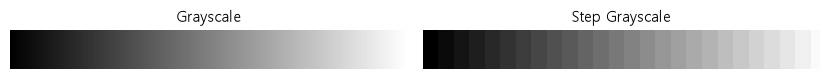

In [9]:
image1 = np.zeros((50, 512), np.uint8)
image2 = image1.copy()
# image2 = np.zeros_like(image1, np.uint8)
rows, cols = image1.shape[:2]
print(image1.shape, np.shape(image1))

for i in range(rows):
    for j in range(cols):
        image1[i, j] = j//2
        image2[i, j] = (j//20)*10

cv2.imshow("Grayscale", image1)
cv2.imshow("Step Grayscale", image2)

## ROI (Region Of Interest) 관심 영역 추출

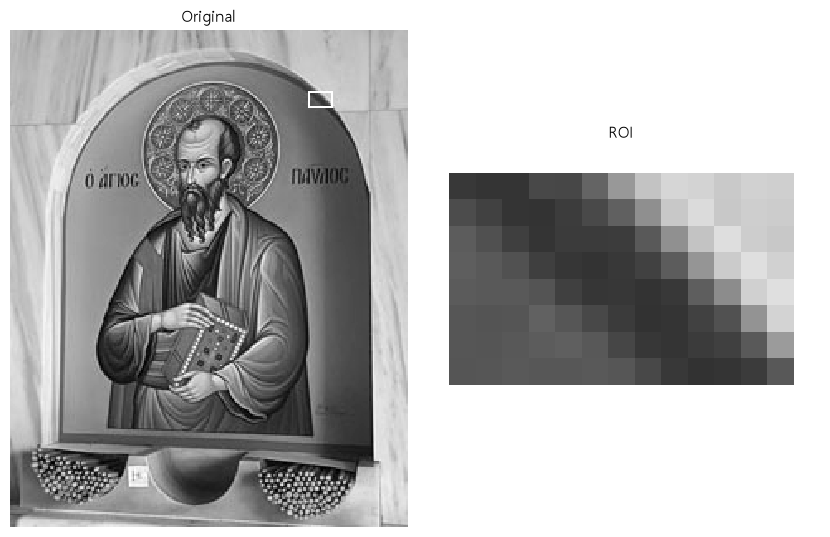

In [11]:
image = cv2.imread("../multi_info/images/pixel.jpg", cv2.IMREAD_GRAYSCALE)
if image is None: raise Exception("File read error")

(x,y), (w,h) = (180, 37), (15, 10)
roi_img = image[y:y+h, x:x+w]
cv2.rectangle(image, (x,y,w,h), 255, 1)

cv2.imshow("Original", image)
resized = cv2.resize(roi_img, (300, 200), interpolation=cv2.INTER_NEAREST_EXACT)
cv2.imshow("ROI", resized)

## 영상 합성

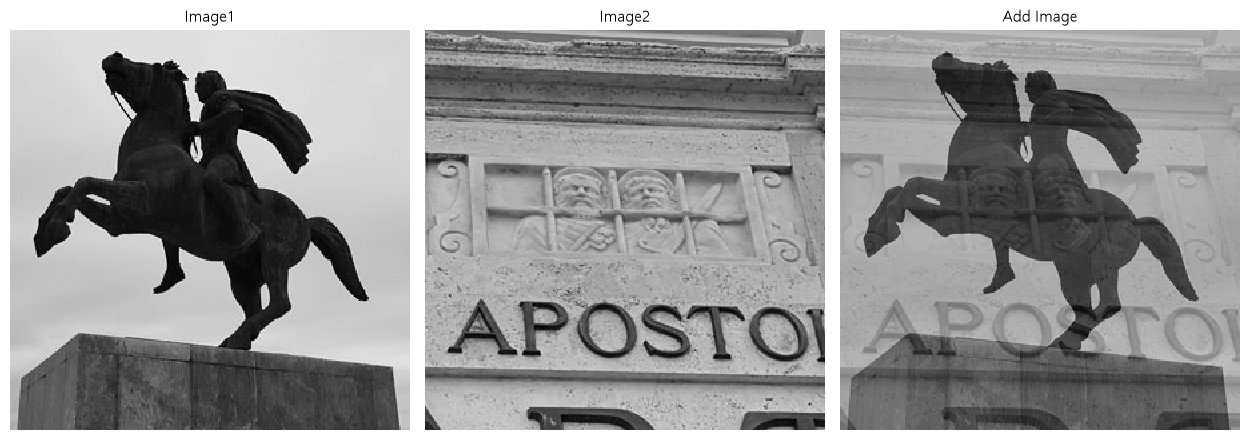

In [13]:
image1 = cv2.imread("../multi_info/images/add1.jpg", cv2.IMREAD_GRAYSCALE)
image2 = cv2.imread("../multi_info/images/add2.jpg", cv2.IMREAD_GRAYSCALE)
cv2.imshow("Image1", image1)
cv2.imshow("Image2", image2)
#image12 = cv2.add((image1*0.5).astype(np.uint8),(image2*0.5).astype(np.uint8)) # uint8인 경우에는 0 ~ 255
image12 = cv2.add(image1*0.6/255.,image2*0.3/255.) # image가 floating point인 경우 0 ~ 1
cv2.imshow("Add Image", image12)

(360, 480, 3) (360, 480, 3)


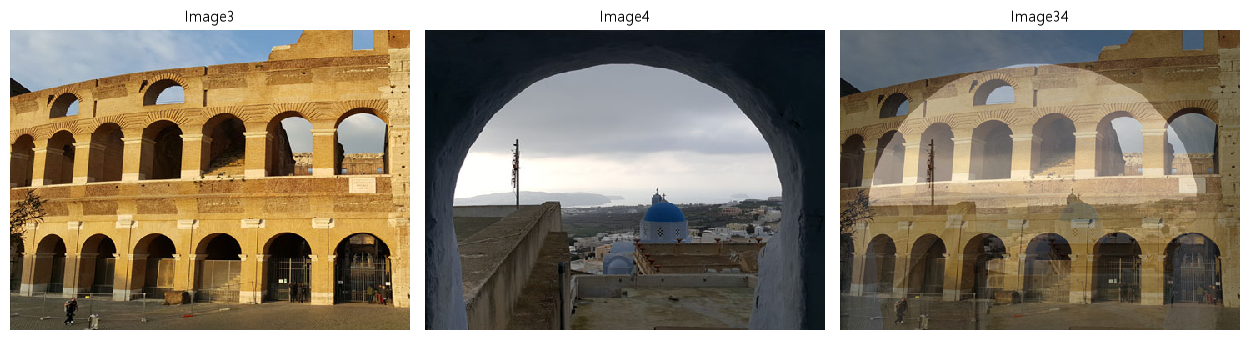

In [14]:
image3 = cv2.imread("../multi_info/images/abs_test1.jpg", cv2.IMREAD_COLOR)
image4 = cv2.imread("../multi_info/images/abs_test2.jpg", cv2.IMREAD_COLOR)
print(image3.shape, image4.shape)
image34 = cv2.add((image3*0.5).astype(np.uint8),(image4*0.5).astype(np.uint8)) # uint8인 경우에는 0 ~ 255

cv2.imshow("Image3", image3)
cv2.imshow("Image4", image4)
cv2.imshow("Image34", image34)

# 히스토그램 구해서 바그래프로 표시

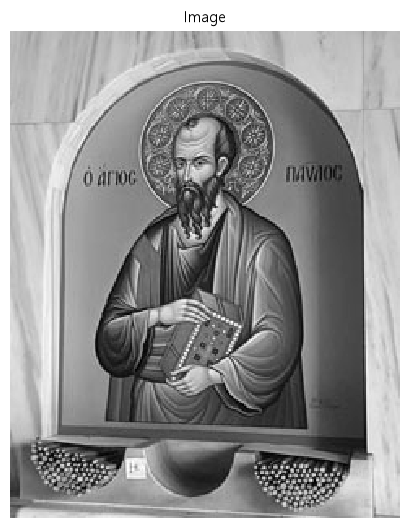

In [15]:
image = cv2.imread("../multi_info/images/pixel.jpg", cv2.IMREAD_GRAYSCALE)
cv2.imshow("Image", image)

In [16]:
# cv2.calcHist()를 이용해서 히스토그램 구현
hsize, ranges = [32], [0, 256]
hist = cv2.calcHist([image], [0], None, hsize, ranges)
print(f"histogram = {hist.flatten()}")

histogram = [  97.  247.  563. 1001. 1401. 1575. 1724. 1951. 2853. 3939. 3250. 2549.
 2467. 2507. 2402. 2418. 2727. 3203. 3410. 3161. 2985. 2590. 3384. 4312.
 4764. 3489. 2802. 2238. 1127.  628.  199.   37.]


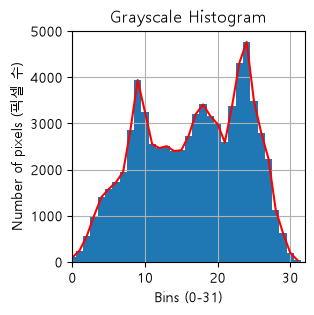

In [18]:
import matplotlib.pyplot as plt
plt.figure(figsize=(3,3))
plt.title("Grayscale Histogram")
plt.xlabel("Bins (0-31)")
plt.ylabel("Number of pixels (픽셀 수)")
plt.bar(np.arange(hsize[0]), hist.flatten(), width=1.0)
plt.plot(np.arange(hsize[0]), hist.flatten(), color='red')
plt.xlim([0, hsize[0]])
plt.grid()
plt.show()